# 0 · Universal approximation theorem

Watch a one-hidden-layer network learn a two-dimensional decision boundary.
Then compare networks with different hidden-layer widths.

## Setup

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from sklearn.datasets import make_moons
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["animation.embed_limit"] = 2**128
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## 1. Synthetic data

In [ ]:
def draw_boundary(ax, model, title):
    with torch.no_grad():
        z = model(grid_tensor).argmax(dim=1).cpu().numpy().reshape(xx.shape)
    ax.clear()
    ax.contourf(xx, yy, z, levels=[-0.5, 0.5, 1.5], alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    ax.set_xlim(X[:, 0].min() - 0.6, X[:, 0].max() + 0.6)
    ax.set_ylim(X[:, 1].min() - 0.6, X[:, 1].max() + 0.6)
    ax.set_title(title)

In [ ]:
X, y = make_moons(n_samples=250, noise=0.2, random_state=42)
X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
y_tensor = torch.tensor(y, dtype=torch.long, device=device)

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.6, X[:, 0].max() + 0.6, 100),
    np.linspace(X[:, 1].min() - 0.6, X[:, 1].max() + 0.6, 100),
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_tensor = torch.tensor(grid, dtype=torch.float32, device=device)


class OneHiddenLayer(nn.Module):
    def __init__(self, hidden_units):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_units),
            nn.Tanh(),
            nn.Linear(hidden_units, 2),
        )

    def forward(self, x):
        return self.net(x)


def train_steps(model, optimizer, criterion, steps=1):
    loss_value = 0.0
    for _ in range(steps):
        optimizer.zero_grad()
        loss = criterion(model(X_tensor), y_tensor)
        loss.backward()
        optimizer.step()
        loss_value = loss.item()
    return loss_value

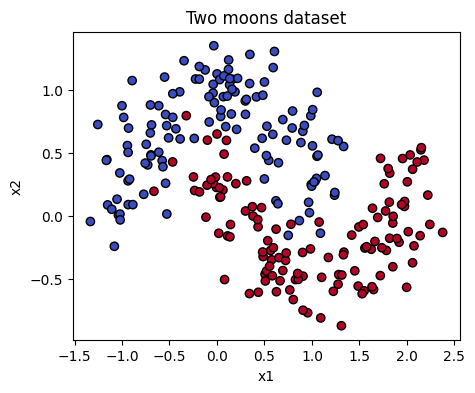

In [7]:
fig_data, ax_data = plt.subplots(figsize=(5, 4))
ax_data.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
ax_data.set_xlabel("x1")
ax_data.set_ylabel("x2")
ax_data.set_title("Two moons dataset")
plt.show()

## 2. Training changes the boundary

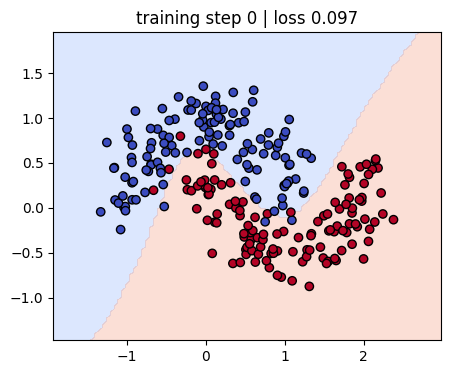

In [8]:
model_epochs = OneHiddenLayer(hidden_units=32).to(device)
optimizer_epochs = optim.Adam(model_epochs.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
fig, ax = plt.subplots(figsize=(5, 4))


def update_epoch(frame):
    loss = train_steps(model_epochs, optimizer_epochs, criterion, steps=5)
    draw_boundary(ax, model_epochs, f"training step {frame * 5} | loss {loss:.3f}")


animation_epochs = FuncAnimation(fig, update_epoch, frames=32, interval=180, repeat=False)
HTML(animation_epochs.to_jshtml())

## 3. More hidden units give more capacity

Each frame trains a fresh network. The number of hidden units increases.

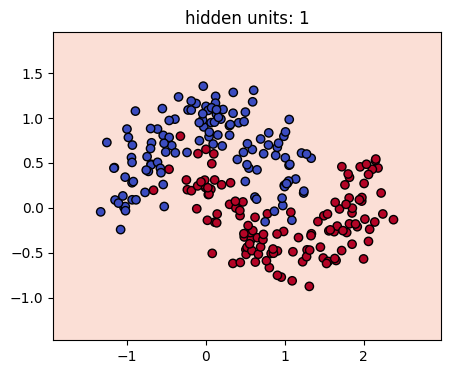

In [10]:
hidden_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 512, 1024]
fig, ax = plt.subplots(figsize=(5, 4))


def update_width(frame):
    hidden_units = hidden_sizes[frame]
    torch.manual_seed(0)
    model = OneHiddenLayer(hidden_units).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    train_steps(model, optimizer, criterion, steps=max(20, hidden_units * 4))
    draw_boundary(ax, model, f"hidden units: {hidden_units}")


animation_width = FuncAnimation(
    fig, update_width, frames=len(hidden_sizes), interval=500, repeat=False
)
HTML(animation_width.to_jshtml())